In [3]:
function harvest(f,m,b)
    z = f+m
    return f*b*(1-exp(-z))/z
end

# dH/df for H = f*b*(1-exp(-z))/z, z = f+m
function dharvest_df(f,m,b)
    z = f+m
    n = b*(m + exp(-z)*(f^2+f*m-m))
    return n/z^2
end

function profit(p,c,f,m,b)
    p*harvest(f,m,b)-c*f
end

function profit_foc(p,c,f,m,b)
    c-p*dharvest_df(f,m,b)
end

# harvest allowed by the control rule (m passed explicitly instead of a global)
function harvest_constaint(b,b_limit,b_target,f_target;m=m)
    f = 0.0
    if b < b_limit
        return 0.0
    elseif b < b_target
        f = f_target * (b-b_limit)/(b_target-b_limit)
    else
        f = f_target
    end
    return harvest(f,m,b)
end 

harvest_constaint (generic function with 1 method)

In [4]:
using Roots

"""
    fisher_response(p, c, m, b; b_limit, b_target, f_target)

Profit-maximizing effort from the first-order condition `profit_foc = 0`,
capped by the harvest control rule `harvest_constaint`.
Returns `(harvest, effort, profit)`.
"""
function fisher_response(p, c, m, b; b_limit=0.0, b_target=1.0, f_target=1.0, f_max=100.0)
    # 1. unconstrained optimum: root of the FOC in f
    foc(f) = profit_foc(p,c,f,m,b)
    if foc(1e-9) >= 0          # marginal profit negative even at zero effort
        f_opt = 0.0
    elseif foc(f_max) <= 0     # no interior root within bounds
        f_opt = f_max
    else
        f_opt = find_zero(foc, (1e-9, f_max), Bisection())
    end
    h_opt = harvest(f_opt,m,b)

    # 2. check against the harvest constraint
    h_con = harvest_constaint(b,b_limit,b_target,f_target; m=m)
    if h_opt <= h_con
        h, f = h_opt, f_opt
    else
        h = h_con
        # effort that yields the constrained harvest (harvest increasing in f)
        f = h_con <= 0 ? 0.0 : find_zero(x -> harvest(x,m,b) - h_con, (1e-9, f_opt), Bisection())
    end
    return (harvest=h, effort=f, profit=p*h - c*f)
end

# example / sanity check: FOC should be ~0 at the unconstrained optimum
let p=1.0, c=0.3, m=0.2, b=1.0
    r = fisher_response(p,c,m,b; b_limit=0.2, b_target=0.6, f_target=0.5)
    println(r)
    r_free = fisher_response(p,c,m,b; b_limit=0.0, b_target=0.0, f_target=100.0)
    println(r_free, "  foc = ", profit_foc(p,c,r_free.effort,m,b))
end

(harvest = 0.3595819258632789, effort = 0.5, profit = 0.20958192586327892)
(harvest = 0.6332753142238121, effort = 1.1574993362064754, profit = 0.2860255133618695)  foc = 5.551115123125783e-17


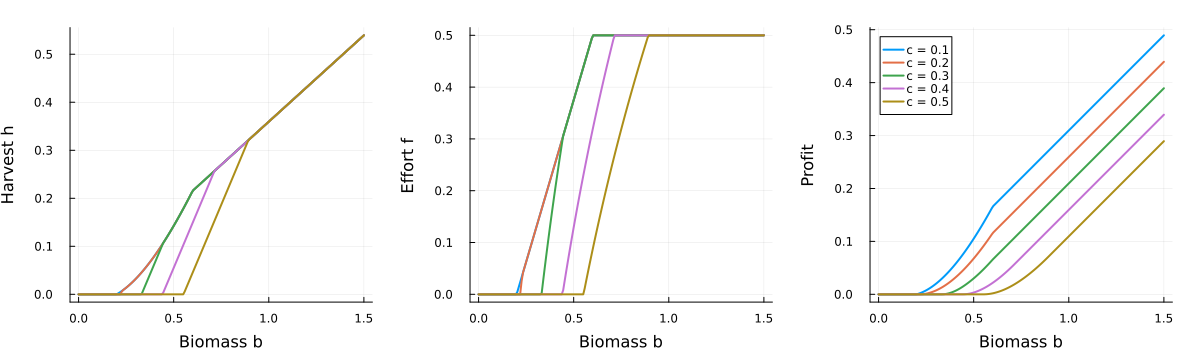

In [5]:
using Plots, LaTeXStrings

# parameters (edit as needed)
p_price = 1.0
m_mort  = 0.2
costs   = [0.1, 0.2, 0.3, 0.4, 0.5]
b_grid  = range(0.0, 1.5, length=200)
ctrl    = (b_limit=0.2, b_target=0.6, f_target=0.5)   # harvest control rule

h_plt = plot(xlabel="Biomass b", ylabel="Harvest h",  legend=false)
f_plt = plot(xlabel="Biomass b", ylabel="Effort f",   legend=false)
π_plt = plot(xlabel="Biomass b", ylabel="Profit",     legend=:topleft)

for c in costs
    res = [fisher_response(p_price, c, m_mort, b; ctrl...) for b in b_grid]
    plot!(h_plt, b_grid, [r.harvest for r in res])
    plot!(f_plt, b_grid, [r.effort  for r in res])
    plot!(π_plt, b_grid, [r.profit  for r in res], label="c = $c")
end

plot(h_plt, f_plt, π_plt, layout=(1,3), size=(1200,350),
     margin=5Plots.mm, linewidth=2)